## IMF Kroupa (2001)

La IMF es una power law por intervalos, $\xi(m) = k_i\, m^{-\alpha_i}$:

| Rango [$M_{\odot}$] | $\alpha$ |
|---|---|
|0.01 - 0.08 | 0.3 |
|0.08 - 0.5  | 1.3 |
|0.5 - 100   | 2.3 |

Las constantes $k_i$ surgen cuando se impone continuidad en cada quiebre, tal que:
$k_i = k_{i-1}\, m_i^{\alpha_i - \alpha_{i-1}}$, con $k_0 = 1$.

Se adopta $M_{\max} = 100\,M_\odot$. Los objetos con $M < 0.08\,M_\odot$ son enanas marrones y se clasifican aparte.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

seed = 42
rng = np.random.default_rng(seed)

mass_ranges = np.array([0.01, 0.08, 0.5, 100])
alphas = np.array([0.3, 1.3, 2.3])

In [2]:
k = np.ones(len(alphas))
for i in range(1, len(alphas)):
    k[i] = k[i-1] * mass_ranges[i]**(alphas[i] - alphas[i-1])

print(k)

[1.   0.08 0.04]


In [3]:
def kroupa_imf(m):
    """
    IMF de Kroupa sin normalizar, continua en los quiebres.
    Entrada: m, masa(s) en Msun (escalar o array)
    Salida:  xi(m); vale 0 fuera de [mass_ranges[0], mass_ranges[-1]]
    """
    m = np.asarray(m, dtype=float)
    xi = np.zeros_like(m)
    for i in range(len(alphas)):
        rango = (m >= mass_ranges[i]) & (m < mass_ranges[i + 1])
        xi[rango] = k[i] * m[rango]**(-alphas[i])
    xi[m == mass_ranges[-1]] = k[-1] * mass_ranges[-1]**(-alphas[-1])   # incluir m_max
    return xi

Para obtener el número de estrellas en un intervalo de masas debemos integrar:

$$ N_{i} = \int_{m_i}^{m_{i+1}} k_i\, m^{-\alpha_i}\,dm $$

Resolvemos la integral y definimos $p_i$ como:

$$ \int m^{-\alpha_i}\, dm = \frac{m^{1-\alpha_i}}{1-\alpha_{i}}, \qquad p_i = 1- \alpha_i $$

Podemos reescribir la integral como:

$$ N_{i} = k_{i}\, \frac{m_{i+1}^{p_i} - m_i^{p_i}}{p_i} = w_i $$

Por lo tanto, $w_i$ representa la integral de la IMF en cada uno de sus tramos.
La suma de las contribuciones de los tramos no da 1, por lo que es necesario normalizar. La constante $a$ se define como:

$$ a = \frac{1}{\sum w_i} $$

De esta forma, $p(m) = a\,\xi(m)$ integra a 1.

La probabilidad de caer en un intervalo es el área bajo la densidad en ese intervalo, por lo que:

$$ P_i = a\, w_i = \frac{w_i}{\sum w_i} $$

La función de distribución acumulada se define como:

$$ F(m) = P(M \leq m) = \int_{m_{\min}}^{m} p(m')\, dm' $$

En los quiebres, $F(m_j) = \sum_{i<j} P_i$.

In [4]:
# Normalización de la IMF por tramos

p = 1 - alphas                                            # exponente de la integral
w = k * (mass_ranges[1:]**p - mass_ranges[:-1]**p) / p    # integral de la IMF en cada tramo
a = 1 / w.sum()                                           # constante de normalización
f_breaks = np.concatenate(([0], np.cumsum(w) * a))        # CDF en cada quiebre

print("P por tramos:", w * a)
print("F en quiebres:", f_breaks)

P por tramos: [0.37148817 0.47811341 0.15039842]
F en quiebres: [0.         0.37148817 0.84960158 1.        ]


### Generador de masas

Los números aleatorios se generan con `np.random.default_rng(seed)`, con `seed = 42`.

`u` son números aleatorios uniformes entre 0 y 1. Con ellos aplicamos el método de la transformada inversa:

$$ m = F^{-1}(u) $$

Primero se determina a qué tramo pertenece cada $u$ usando `searchsorted` y la CDF en los quiebres:

F en quiebres: [0, 0.371, 0.850, 1]

Por ejemplo, $u = 0.15$ pertenece al primer tramo y $u = 0.5$ al segundo. Dentro del tramo $i$ se despeja:

$$ M = \left[ m_i^{p_i} + \frac{p_i\,(u - F(m_i))}{a\,k_i} \right]^{1/p_i} $$

In [5]:
def sample_kroupa(n, rng):
    """
    Genera masas iniciales siguiendo la IMF de Kroupa (transformada inversa por tramos).
    Entradas: n, número de estrellas; rng, np.random.Generator
    Salida:   array (n,) de masas en Msun
    """
    u = rng.uniform(size=n)
    i = np.searchsorted(f_breaks, u, side='right') - 1    # tramo de cada u
    pi = p[i]
    return (mass_ranges[i]**pi + pi * (u - f_breaks[i]) / (a * k[i]))**(1 / pi)

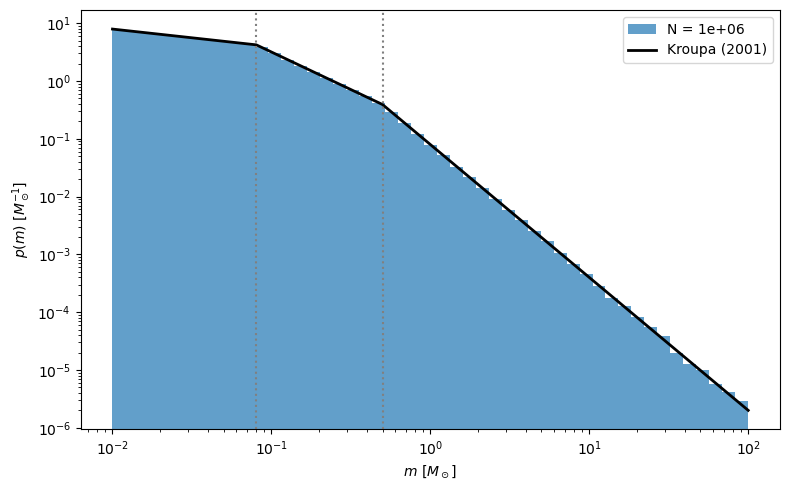

In [14]:
N = 10**6
M = sample_kroupa(N, rng)

bins = np.logspace(np.log10(mass_ranges[0]), np.log10(mass_ranges[-1]), 50)

plt.figure(figsize=(8, 5))
plt.hist(M, bins=bins, density=True, alpha=0.7, label=f'N = {N:.0e}' )
m_plot = np.logspace(np.log10(mass_ranges[0]), np.log10(mass_ranges[-1]), 1000)
plt.plot(m_plot, a * kroupa_imf(m_plot), 'k-', lw=2, label='Kroupa (2001)')

for mb in mass_ranges[1:-1]:
    plt.axvline(mb, ls=':', c='gray')

plt.xscale('log')
plt.yscale('log')

plt.xlabel(r"$m\ [M_\odot]$")
plt.ylabel(r"$p(m)\ [M_\odot^{-1}]$")

plt.legend()
plt.tight_layout()
plt.show()

In [15]:
# Validación numérica con la misma muestra M del gráfico (no se vuelve a sortear)
print("Masa mínima:", M.min())
print("Masa máxima:", M.max())
print("Número de objetos:", len(M))

print("\nTramo            Teoría    Muestra")
for i in range(len(alphas)):
    lo, hi = mass_ranges[i], mass_ranges[i + 1]
    frac = np.mean((M >= lo) & (M < hi))
    print(f"{lo:5.2f} – {hi:6.2f}   {w[i]*a:.4f}    {frac:.4f}")

Masa mínima: 0.01000003140506195
Masa máxima: 95.99517617101033
Número de objetos: 1000000

Tramo            Teoría    Muestra
 0.01 –   0.08   0.3715    0.3714
 0.08 –   0.50   0.4781    0.4789
 0.50 – 100.00   0.1504    0.1498


## Parte I.b: Historia de formación estelar y tiempo de vida en MS

- SFR constante: $t_{\rm birth} \sim U(0, T_{MW})$, con $T_{MW} = 10$ Gyr
- Edad actual: $t_{\rm age} = T_{MW} - t_{\rm birth}$
- Tiempo de vida en MS: $t_{MS} = 10\ {\rm Gyr}\,(M/M_\odot)^{-2.5}$
- Si $t_{\rm age} < t_{MS}$ la estrella sigue en MS; si no, evolucionó.
- Los objetos con $M < 0.08\,M_\odot$ son enanas marrones (BD) y se clasifican aparte.

In [8]:
T_MW = 10.0        # Gyr, edad de la galaxia
T_MS_SUN = 10.0    # Gyr, tiempo de vida en MS de una estrella de 1 Msun
MS_EXP = -2.5      # t_MS ∝ M^-2.5
M_H_BURN = 0.08    # Msun, bajo esto no hay fusión de H (enana marrón)

In [9]:
def sample_birth_times(n, rng):
    """Tiempos de nacimiento [Gyr] con SFR constante: t_birth ~ U(0, T_MW)."""
    return rng.uniform(0.0, T_MW, size=n)

def ms_lifetime(M):
    """Tiempo de vida en secuencia principal [Gyr] para masa(s) M [Msun]."""
    return T_MS_SUN * M**MS_EXP

In [ ]:
birth_times = sample_birth_times(N, rng) 
print(f"media: {birth_times.mean():.4f}   (teoría: {T_MW/2:.4f})")
print(f"std:   {birth_times.std():.4f}   (teoría: {T_MW/np.sqrt(12):.4f})")

media: 4.9982   (teoría: 5.0000)
std:   2.8858   (teoría: 2.8868)


### Clasificación: MS o evolucionada

Cada estrella tiene una masa M y un tiempo de que nació birthtime
Si $t_{\rm age} > t_{MS}$, la estrella ya salió de la secuencia principal.

In [ ]:
t_age = T_MW - birth_times
t_MS = ms_lifetime(M)

is_BD = M < M_H_BURN                           # Enanas marrones niggi
is_evolved = (M >= M_H_BURN) & (t_age > t_MS)  # Estrellas evolucionadas
is_MS = (M >= M_H_BURN) & (t_age <= t_MS)      # Estrellas en secuencia principal

n_stars = np.sum(M >= M_H_BURN)

print(f"Enanas marrones: {is_BD.mean():.4f} del total")
print(f"MS:              {is_MS.sum()/n_stars:.4f} de las estrellas")
print(f"Evolucionadas:   {is_evolved.sum()/n_stars:.4f} de las estrellas")
print(f"Masa mínima evolucionada: {M[is_evolved].min():.3f} Msun")

Enanas marrones: 0.3712 del total
MS:              0.9361 de las estrellas
Evolucionadas:   0.0639 de las estrellas
Masa mínima evolucionada: 1.002 Msun


In [12]:
#Clasificación de las estrellas evolucionadas en WD, NS y BH según la masa inicial

if is_evolved.sum() > 0:
    M_evolved = M[is_evolved]
    M_WD = M_evolved[M_evolved < 8.0]
    M_NS = M_evolved[(M_evolved >= 8.0) & (M_evolved < 20.0)]
    M_BH = M_evolved[M_evolved >= 20.0]

    print(f"Estrellas evolucionadas: {is_evolved.sum()} de {n_stars} estrellas")
    print(f" - Enanas blancas (M < 8 Msun): {len(M_WD)}")
    print(f" - Estrellas de neutrones (8 <= M < 20 Msun): {len(M_NS)}")
    print(f" - Agujeros negros (M >= 20 Msun): {len(M_BH)}")

Estrellas evolucionadas: 40204 de 628762 estrellas
 - Enanas blancas (M < 8 Msun): 36288
 - Estrellas de neutrones (8 <= M < 20 Msun): 2812
 - Agujeros negros (M >= 20 Msun): 1104
